In [251]:
import re
import os
import copy
import random
import librosa
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from datasets import load_dataset
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix,ConfusionMatrixDisplay

## Project Configuration

In [252]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------------- Split ----------------
SPLIT_MODE = "speaker"
# random
# speaker

# ---------------- Features ----------------
USE_DELTA = True
# False -> MFCC
# True  -> MFCC + Delta + DeltaDelta

# ---------------- Padding ----------------
KEEP = "last"
# first
# last

# ---------------- Model ----------------
MODEL_NAME = "plain"
# plain
# residual

# ---------------- Hyperparameters ----------------
SR = 16000
N_MFCC = 40
MAX_LEN = 300
BATCH_SIZE = 32
NUM_CLASSES = 4
LEARNING_RATE = 1e-3
NUM_EPOCHS = 30

## Loading Dataset

In [253]:
dataset = load_dataset("AbstractTTS/IEMOCAP")
dataset = dataset["train"]

print(f"Total number of samples: {len(dataset)}")

selected_emotions = ["angry", "happy", "neutral", "sad"]
dataset = dataset.filter(
    lambda sample: sample["major_emotion"] in selected_emotions
)

print(f"Number of selected samples: {len(dataset)}")

label_map = {
    "angry": 0,
    "happy": 1,
    "neutral": 2,
    "sad": 3
}

def encode_label(sample):
    sample["label"] = label_map[sample["major_emotion"]]
    return sample

dataset = dataset.map(encode_label)

def extract_speaker(sample):
    speaker = re.match(r"(Ses\d+[MF])", sample["file"]).group(1)
    sample["speaker"] = speaker
    return sample

dataset = dataset.map(extract_speaker)

Total number of samples: 10039
Number of selected samples: 4901


## Plot Label Distribution

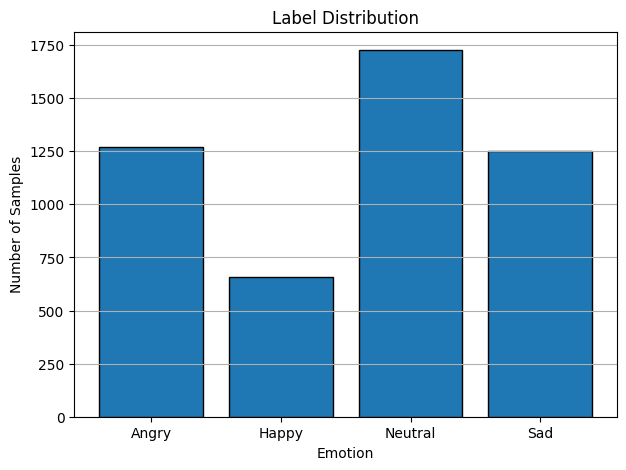

In [254]:
labels = dataset["label"]
label_counter = Counter(labels)
emotion_names = ["Angry", "Happy", "Neutral", "Sad"]

counts = [
    label_counter[0],
    label_counter[1],
    label_counter[2],
    label_counter[3]
]

plt.figure(figsize=(7, 5))
plt.bar(emotion_names, counts, edgecolor="black")

plt.title("Label Distribution")
plt.xlabel("Emotion")
plt.ylabel("Number of Samples")
plt.grid(axis="y")
plt.savefig("label_distribution.png", dpi=300)
plt.show()

## Plot Audio Duration Distribution

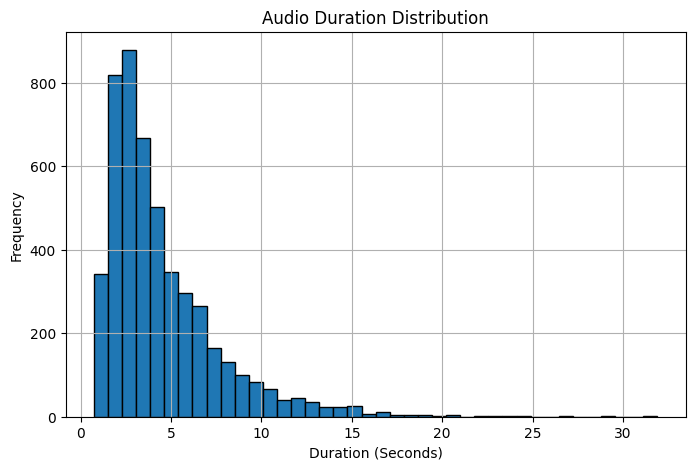

In [255]:
durations = np.array([
    len(sample["audio"]["array"]) /
    sample["audio"]["sampling_rate"]
    for sample in dataset
])

plt.figure(figsize=(8, 5))
plt.hist(durations, bins=40, edgecolor="black")
plt.xlabel("Duration (Seconds)")
plt.ylabel("Frequency")
plt.title("Audio Duration Distribution")
plt.grid()
plt.savefig("duration_distribution.png", dpi=300)
plt.show()

## Duration Statistics

In [256]:
print("\nAudio Duration Statistics")
print("-" * 35)
print(f"Mean Duration     : {durations.mean():.2f} seconds")
print(f"Std Duration      : {durations.std():.2f} seconds")
print(f"Minimum Duration  : {durations.min():.2f} seconds")
print(f"Maximum Duration  : {durations.max():.2f} seconds")

print("\nLabel Distribution")
print("-" * 35)
for emotion, count in zip(emotion_names, counts):
    print(f"{emotion:<10}: {count}")


Audio Duration Statistics
-----------------------------------
Mean Duration     : 4.48 seconds
Std Duration      : 3.14 seconds
Minimum Duration  : 0.73 seconds
Maximum Duration  : 31.91 seconds

Label Distribution
-----------------------------------
Angry     : 1269
Happy     : 656
Neutral   : 1726
Sad       : 1250


## Random Dataset Split

In [257]:
indices = list(range(len(dataset)))

train_idx, test_idx = train_test_split(indices, test_size=0.20, random_state=SEED, stratify=dataset["label"])
train_labels = [dataset[i]["label"] for i in train_idx]

train_idx, valid_idx = train_test_split( train_idx, test_size=0.125, random_state=SEED, stratify=train_labels)

train_data = dataset.select(train_idx)
valid_data = dataset.select(valid_idx)
test_data = dataset.select(test_idx)

print("Random Split")
print("---------------------------")
print("Train:", len(train_data))
print("Validation:", len(valid_data))
print("Test:", len(test_data))

Random Split
---------------------------
Train: 3430
Validation: 490
Test: 981


## Speaker Independent Split

In [258]:
speakers = sorted(list(set(dataset["speaker"])))

print("\nSpeakers")
print("---------------------------")
print(speakers, "\n")
print("Number of speakers:", len(speakers))

train_speakers = ["Ses03M","Ses01F","Ses05M","Ses01M","Ses03F","Ses02F","Ses04F"]
valid_speakers = ["Ses04M"]
test_speakers = ["Ses05F","Ses02M"]

speaker_train = dataset.filter(lambda x: x["speaker"] in train_speakers)
speaker_valid = dataset.filter(lambda x: x["speaker"] in valid_speakers)
speaker_test = dataset.filter(lambda x: x["speaker"] in test_speakers)

print("\nSpeaker Independent Split")
print("---------------------------")
print("Train:", len(speaker_train))
print("Validation:", len(speaker_valid))
print("Test:", len(speaker_test))



Speakers
---------------------------
['Ses01F', 'Ses01M', 'Ses02F', 'Ses02M', 'Ses03F', 'Ses03M', 'Ses04F', 'Ses04M', 'Ses05F', 'Ses05M'] 

Number of speakers: 10

Speaker Independent Split
---------------------------
Train: 3534
Validation: 424
Test: 943


## Split Mode

In [259]:
if SPLIT_MODE == "random":
    train_data = dataset.select(train_idx)
    valid_data = dataset.select(valid_idx)
    test_data = dataset.select(test_idx)

elif SPLIT_MODE == "speaker":
    train_data = speaker_train
    valid_data = speaker_valid
    test_data = speaker_test

##  MFCC Feature Extraction Function

In [260]:
def extract_features(audio, sr, n_mfcc=40, use_delta=False):
    mfcc = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=n_mfcc, hop_length=512)

    if not use_delta:
        return mfcc.astype(np.float32)

    delta = librosa.feature.delta( mfcc, order=1)
    delta2 = librosa.feature.delta(mfcc, order=2)
    features = np.concatenate(
        [
            mfcc,
            delta,
            delta2
        ],
        axis=0
    )

    return features.astype(np.float32)

sample = dataset[0]
audio = sample["audio"]["array"]
sr = sample["audio"]["sampling_rate"]

mfcc = extract_features(audio, sr, use_delta=False)
mfcc_delta = extract_features(audio, sr, use_delta=True)

print("Feature Shapes")
print("---------------------------")
print("MFCC Only :", mfcc.shape)
print("MFCC + Delta + Delta2 :", mfcc_delta.shape)

Feature Shapes
---------------------------
MFCC Only : (40, 61)
MFCC + Delta + Delta2 : (120, 61)


## Standardization of Sequence Lengths

In [261]:
MAX_LEN = 300

def pad_or_truncate(features, max_len=MAX_LEN, keep="first"):
    """
    keep="first" : Keep the beginning of the utterance
    keep="last"  : Keep the end of the utterance
    """
    T = features.shape[1]

    if T > max_len:
        if keep == "first":
            features = features[:, :max_len]

        elif keep == "last":
            features = features[:, -max_len:]

    else:
        pad = max_len - T
        features = np.pad(features, ((0, 0), (0, pad)), mode="constant")

    return features

features = extract_features(audio,sr,use_delta=False)
features = pad_or_truncate(features, keep=KEEP)


## Extract Features from Dataset

In [262]:
def extract_dataset_features(dataset, use_delta=False, keep="front"):
    feature_list=[]
    label_list=[]
    #mask_list=[]

    for sample in dataset:

        audio=sample["audio"]["array"]
        sr=sample["audio"]["sampling_rate"]

        # Extract MFCC
        features=extract_features(audio, sr, use_delta=use_delta)
        original_length=features.shape[1]

        # Pad / Truncate
        features=pad_or_truncate(features, keep=keep)

        # Create Mask
        #mask=create_mask(original_length)

        feature_list.append(features)
        label_list.append(sample["label"])
        #mask_list.append(mask)

    feature_array=np.stack(feature_list)
    label_array=np.array(label_list)
    #mask_array=np.stack(mask_list)

    return feature_array,label_array

train_features, train_labels = extract_dataset_features(train_data, use_delta=USE_DELTA, keep=KEEP)

val_features, val_labels = extract_dataset_features(valid_data, use_delta=USE_DELTA, keep=KEEP)

test_features, test_labels = extract_dataset_features(test_data, use_delta=USE_DELTA, keep=KEEP)

## Feature Normalization

In [263]:
mean = train_features.mean(axis=(0, 2), keepdims=True)
std = train_features.std(axis=(0, 2), keepdims=True)

train_features = (train_features - mean) / (std + 1e-8)
val_features = (val_features - mean) / (std + 1e-8)
test_features = (test_features - mean) / (std + 1e-8)

print("Feature Shapes")
print("---------------------------")
print("Train features :", train_features.shape)
print("Validation features :", val_features.shape)
print("Test features :", test_features.shape)

Feature Shapes
---------------------------
Train features : (3534, 120, 300)
Validation features : (424, 120, 300)
Test features : (943, 120, 300)


## PyTorch Dataset

In [264]:
class EmotionDataset(Dataset):

    def __init__(self, features, labels):
        self.features = torch.tensor(features, dtype=torch.float32)
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):

        return (self.features[index], self.labels[index])


train_dataset = EmotionDataset(train_features, train_labels)
val_dataset = EmotionDataset(val_features, val_labels)
test_dataset = EmotionDataset(test_features, test_labels)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

## CNN Block

In [265]:
class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv1d(in_channels, out_channels,kernel_size=3,stride=1,padding=1 ),

            nn.BatchNorm1d(out_channels),

            nn.ReLU(),

            nn.MaxPool1d(kernel_size=2, stride=2)
        )

    def forward(self,x):
        return self.block(x)

## Residual Block

In [266]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv1 = nn.Conv1d( in_channels, out_channels, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm1d(out_channels)

        self.conv2 = nn.Conv1d(out_channels, out_channels, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm1d(out_channels)

        self.relu = nn.ReLU()
        self.pool = nn.MaxPool1d(2)

        if in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv1d(in_channels, out_channels, kernel_size=1),
                nn.BatchNorm1d(out_channels)
            )

        else:
            self.shortcut = nn.Identity()

    def forward(self,x):
        identity = self.shortcut(x)
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + identity
        out = self.relu(out)
        out = self.pool(out)

        return out

## Plain 1D CNN

In [267]:
class PlainCNN(nn.Module):
    def __init__(self, input_dim, num_classes=4):
        super().__init__()

        self.encoder = nn.Sequential(
            ConvBlock(input_dim,64),
            ConvBlock(64,128),
            ConvBlock(128,256)
        )
        
        self.pool = nn.AdaptiveAvgPool1d(1)

        self.classifier = nn.Sequential(
            nn.Linear(256,128),
            nn.ReLU(),
            nn.Linear(128,num_classes)
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.pool(x).squeeze(-1)
        return self.classifier(x)

## Residual 1D CNN

In [268]:
class ResidualCNN(nn.Module):
    def __init__(self, input_dim, num_classes=4):
        super().__init__()

        self.encoder = nn.Sequential(
            ResidualBlock(input_dim,64),
            ResidualBlock(64,128),
            ResidualBlock(128,256)
        )

        self.pool = nn.AdaptiveAvgPool1d(1)
        self.classifier = nn.Sequential(
            nn.Linear(256,128),
            nn.ReLU(),
            nn.Linear(128,num_classes)
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.pool(x).squeeze(-1)
        return self.classifier(x)

## Training Configuration

In [269]:
INPUT_DIM = train_features.shape[1]

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

if MODEL_NAME == "plain":
    model = PlainCNN(INPUT_DIM)

elif MODEL_NAME == "residual":
    model = ResidualCNN(INPUT_DIM)

model = model.to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

## Train Function

In [270]:
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs, device):

    best_model = copy.deepcopy(model.state_dict())
    best_val_loss = np.inf

    train_losses = []
    val_losses = []

    for epoch in range(num_epochs):

        # Train
        model.train()
        running_loss = 0

        for features, labels in train_loader:
            features = features.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(features)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        train_loss = running_loss / len(train_loader)

        # Validation
        model.eval()
        running_loss = 0
        with torch.no_grad():
            for features, labels in val_loader:

                features = features.to(device)
                labels = labels.to(device)

                outputs = model(features)
                loss = criterion(outputs, labels)
                running_loss += loss.item()

        val_loss = running_loss / len(val_loader)
        train_losses.append(train_loss)
        val_losses.append(val_loss)

        print(
            f"Epoch {epoch+1:02d}/{num_epochs} | "
            f"Train Loss = {train_loss:.4f} | "
            f"Validation Loss = {val_loss:.4f}"
        )

        # Save Best Model
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model = copy.deepcopy(model.state_dict())
            torch.save(best_model, "best_model.pth")

    model.load_state_dict(best_model)

    return model, train_losses, val_losses

## Evaluation Function

In [271]:
def evaluate_model(model, loader, device):
    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for features, labels in loader:

            features = features.to(device)
            labels = labels.to(device)

            outputs = model(features)
            prediction = outputs.argmax(1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(prediction.cpu().numpy())

    accuracy = accuracy_score(y_true, y_pred)
    weighted_f1 = f1_score( y_true, y_pred, average="weighted")
    macro_f1 = f1_score( y_true, y_pred, average="macro")

    return (accuracy, weighted_f1,macro_f1, y_true, y_pred)

## Train Model & Test Evaluation

Plain 1D CNN
Epoch 01/30 | Train Loss = 1.0759 | Validation Loss = 0.9426
Epoch 02/30 | Train Loss = 0.9372 | Validation Loss = 1.0113
Epoch 03/30 | Train Loss = 0.8594 | Validation Loss = 0.9168
Epoch 04/30 | Train Loss = 0.7736 | Validation Loss = 0.9872
Epoch 05/30 | Train Loss = 0.7000 | Validation Loss = 1.0373
Epoch 06/30 | Train Loss = 0.6244 | Validation Loss = 0.9315
Epoch 07/30 | Train Loss = 0.5458 | Validation Loss = 1.5284
Epoch 08/30 | Train Loss = 0.4921 | Validation Loss = 1.2863
Epoch 09/30 | Train Loss = 0.4521 | Validation Loss = 1.3250
Epoch 10/30 | Train Loss = 0.3836 | Validation Loss = 1.7281
Epoch 11/30 | Train Loss = 0.3174 | Validation Loss = 1.4456
Epoch 12/30 | Train Loss = 0.2869 | Validation Loss = 1.7640
Epoch 13/30 | Train Loss = 0.2403 | Validation Loss = 2.2059
Epoch 14/30 | Train Loss = 0.1641 | Validation Loss = 2.0753
Epoch 15/30 | Train Loss = 0.1589 | Validation Loss = 2.3827
Epoch 16/30 | Train Loss = 0.1604 | Validation Loss = 3.9660
Epoch 17/30

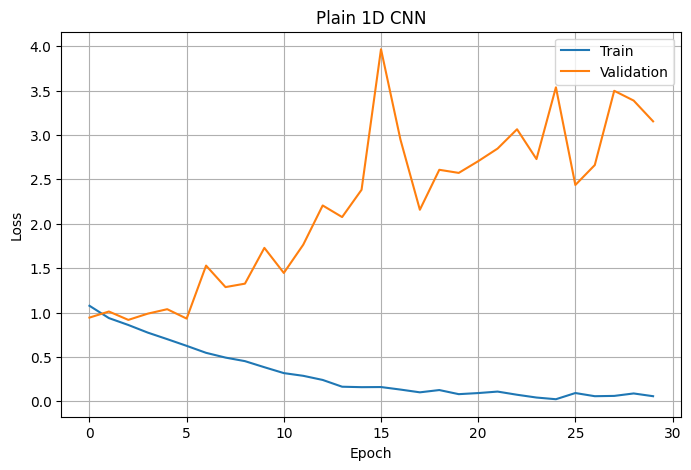

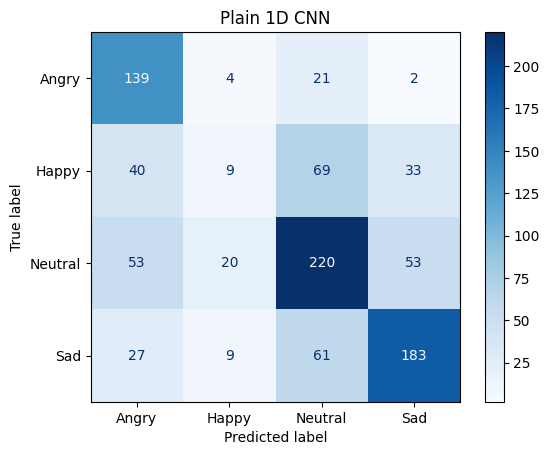


Final Results
          Model  Accuracy  Weighted F1  Macro F1
0  Plain 1D CNN  0.584305     0.552476  0.506324


In [272]:
results = []
models = {
    "Plain 1D CNN": PlainCNN
    #"Residual 1D CNN": ResidualCNN
}

for model_name, ModelClass in models.items():

    print(model_name)
    print("=" * 60)

    model = ModelClass(input_dim=INPUT_DIM, num_classes=NUM_CLASSES).to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(),lr=LEARNING_RATE)

    model, train_losses, val_losses = train_model(
        model,
        train_loader,
        val_loader,
        criterion,
        optimizer,
        NUM_EPOCHS,
        DEVICE
    )

    accuracy, weighted_f1, macro_f1, y_true, y_pred = evaluate_model(
        model,
        test_loader,
        DEVICE
    )

    print(f"Accuracy    : {accuracy:.4f}")
    print(f"Weighted F1 : {weighted_f1:.4f}")
    print(f"Macro F1    : {macro_f1:.4f}")

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Weighted F1": weighted_f1,
        "Macro F1": macro_f1
    })

    # Loss Curve
    plt.figure(figsize=(8,5))
    plt.plot(train_losses, label="Train")
    plt.plot(val_losses, label="Validation")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(model_name)
    plt.grid(True)
    plt.legend()
    plt.show()

    # Confusion Matrix
    class_names = [
        "Angry",
        "Happy",
        "Neutral",
        "Sad"
    ]

    cm = confusion_matrix(y_true, y_pred)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    disp.plot(cmap="Blues", values_format="d")
    plt.title(model_name)
    plt.show()


results = pd.DataFrame(results)

print("\nFinal Results")
print(results)    